# 1. Thu thập và đọc dữ liệu


In [16]:
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import seaborn as sns
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("GBT_Classifier").getOrCreate()
df = spark.read.parquet("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/processed/citation_ml_dataset.parquet")


# 2. Thống kê dữ liệu


In [17]:
print("Số lượng dòng:", df.count())
print("Số lượng cột:", len(df.columns))
df.printSchema()


Số lượng dòng: 694450
Số lượng cột: 13
root
 |-- paper_id: long (nullable = true)
 |-- pub_year: long (nullable = true)
 |-- past_in_degree: long (nullable = true)
 |-- num_authors: long (nullable = true)
 |-- num_topics: long (nullable = true)
 |-- pagerank_score: double (nullable = true)
 |-- paper_age: long (nullable = true)
 |-- citation_velocity: double (nullable = true)
 |-- paper_feat_128d: vector (nullable = true)
 |-- delta_c: long (nullable = true)
 |-- ogb_split: string (nullable = true)
 |-- label: double (nullable = true)
 |-- temporal_split: string (nullable = true)



# 3. Trực quan hóa dữ liệu


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_6537/3789449976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])


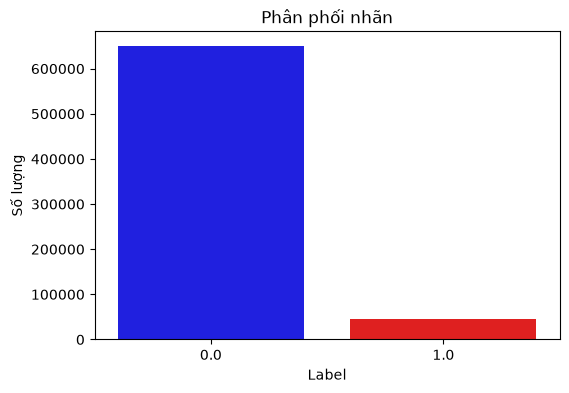

   label   count
0    0.0  649837
1    1.0   44613


In [18]:
label_counts = df.groupBy("label").count().toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])
plt.title("Phân phối nhãn")
plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.show()
print(label_counts)


# 4. Tiền xử lý dữ liệu và chia tập dữ liệu


In [19]:
features = ["citation_velocity", "pagerank_score", "paper_age"]
target = "label"

assembler = VectorAssembler(inputCols=features, outputCol="raw_features")
assembled_df = assembler.transform(df)

train_data = assembled_df.filter(assembled_df["temporal_split"] == "train")
val_data = assembled_df.filter(assembled_df["temporal_split"] == "valid")
test_data = assembled_df.filter(assembled_df["temporal_split"] == "test")

print("Train:", train_data.count())
print("Validation:", val_data.count())
print("Test:", test_data.count())

scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)
scaler_model = scaler.fit(train_data)

train_scaled = scaler_model.transform(train_data)
val_scaled = scaler_model.transform(val_data)
test_scaled = scaler_model.transform(test_data)


Train: 559373
Validation: 70198
Test: 64879


In [20]:
from pyspark.sql.functions import col, when

# Đếm số lượng từng lớp
counts = {
    r["label"]: r["count"]
    for r in train_scaled.groupBy("label").count().collect()
}

total = sum(counts.values())

# Tính trọng số cho từng lớp
weight_0 = total / (2 * counts[0.0])
weight_1 = total / (2 * counts[1.0])

# Gán trọng số
train_weighted = train_scaled.withColumn(
    "class_weight",
    when(col("label") == 0.0, weight_0)
    .otherwise(weight_1)
)

train_weighted.groupBy("label").agg(
    {"class_weight": "avg"}
).show()

+-----+------------------+
|label| avg(class_weight)|
+-----+------------------+
|  0.0|0.5273511815538862|
|  1.0| 9.640372949124767|
+-----+------------------+



# 5. Model Training (Huấn luyện mô hình)


In [21]:
from pyspark.ml.tuning import ParamGridBuilder

gbt = GBTClassifier(featuresCol="scaled_features", labelCol=target, seed=42, weightCol="class_weight")

param_grid = ParamGridBuilder().addGrid(gbt.maxDepth, [4, 6, 8]).addGrid(gbt.maxIter, [10, 15, 20]).build()

evaluator_tune = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="rawPrediction", metricName="areaUnderPR")

best_score = -1.0
gbt_model = None
best_params = None

for params in param_grid:
    candidate_model = gbt.copy(params).fit(train_weighted)
    val_pr = evaluator_tune.evaluate(candidate_model.transform(val_scaled))
    if val_pr > best_score:
        best_score = val_pr
        gbt_model = candidate_model
        best_params = params

d = best_params[gbt.maxDepth]
it = best_params[gbt.maxIter]
print(f"Best Params: maxDepth={d}, maxIter={it} (Val PR-AUC: {best_score:.4f})")
print("Feature Importances:", gbt_model.featureImportances)


Best Params: maxDepth=4, maxIter=15 (Val PR-AUC: 0.6622)
Feature Importances: (3,[0,1,2],[0.9631600087533126,0.02061325939168839,0.01622673185499887])


# 6. Model Validation (Kiểm định trên tập Validation)


In [22]:
val_predictions = gbt_model.transform(val_scaled)

pr_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="rawPrediction", metricName="areaUnderPR")
roc_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="rawPrediction", metricName="areaUnderROC")
f1_evaluator = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1")

print("Validation PR-AUC:", pr_evaluator.evaluate(val_predictions))
print("Validation ROC-AUC:", roc_evaluator.evaluate(val_predictions))
print("Validation F1-Score:", f1_evaluator.evaluate(val_predictions))


Validation PR-AUC: 0.6617697022491523
Validation ROC-AUC: 0.913356306522581
Validation F1-Score: 0.8660041051189641


# 7. Model Testing (Đánh giá trên tập Test)


In [23]:
test_predictions = gbt_model.transform(test_scaled)

print("Test PR-AUC:", pr_evaluator.evaluate(test_predictions))
print("Test ROC-AUC:", roc_evaluator.evaluate(test_predictions))
print("Test F1-Score:", f1_evaluator.evaluate(test_predictions))


Test PR-AUC: 0.5384703391344166
Test ROC-AUC: 0.7868412622431965
Test F1-Score: 0.8560234715436048


In [24]:
test_predictions.select("paper_id", "label", "prediction", "rawPrediction").show(10, truncate=False)


+--------+-----+----------+------------------------------------------+
|paper_id|label|prediction|rawPrediction                             |
+--------+-----+----------+------------------------------------------+
|3383    |0.0  |0.0       |[1.306598958876106,-1.306598958876106]    |
|9588    |0.0  |0.0       |[1.306598958876106,-1.306598958876106]    |
|10024   |0.0  |0.0       |[0.4291201288885051,-0.4291201288885051]  |
|87870   |1.0  |1.0       |[-1.4120482944502557,1.4120482944502557]  |
|455608  |1.0  |1.0       |[-1.3469679505429832,1.3469679505429832]  |
|456269  |0.0  |0.0       |[1.306598958876106,-1.306598958876106]    |
|466691  |0.0  |1.0       |[-0.44113296447940875,0.44113296447940875]|
|472841  |0.0  |0.0       |[0.3753571943579891,-0.3753571943579891]  |
|478300  |0.0  |0.0       |[1.306598958876106,-1.306598958876106]    |
|493006  |0.0  |1.0       |[-0.7283210231441979,0.7283210231441979]  |
+--------+-----+----------+------------------------------------------+
only s

In [25]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# 1. Accuracy
acc_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="accuracy")

# 2. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=1.0)
prec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0)
rec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0)
f1_1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=1.0)

# 3. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=0)
prec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=0.0)
rec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=0.0)
f1_0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=0.0)

print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 1): {prec1_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 1):    {rec1_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 1):  {f1_1_eval.evaluate(test_predictions):.4f}")


print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 0): {prec0_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 0):    {rec0_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 0):  {f1_0_eval.evaluate(test_predictions):.4f}")

print(f"Test F1-Score (Weighted): {f1_evaluator.evaluate(test_predictions):.4f}")

Test Accuracy:          0.8494
Test Precision (Lớp 1): 0.4558
Test Recall (Lớp 1):    0.5661
Test F1-Score (Lớp 1):  0.8560
Test Accuracy:          0.8494
Test Precision (Lớp 0): 0.9292
Test Recall (Lớp 0):    0.8938
Test F1-Score (Lớp 0):  0.8560
Test F1-Score (Weighted): 0.8560


# 8. Trích xuất kết quả dự đoán


In [26]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc

pred_pd = test_predictions.select("label", "prediction", "rawPrediction").toPandas()
y_true = pred_pd["label"].values
y_pred = pred_pd["prediction"].values
y_score = pred_pd["rawPrediction"].apply(lambda v: float(v[1])).values


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


# 9. Biểu đồ 1: Confusion Matrix


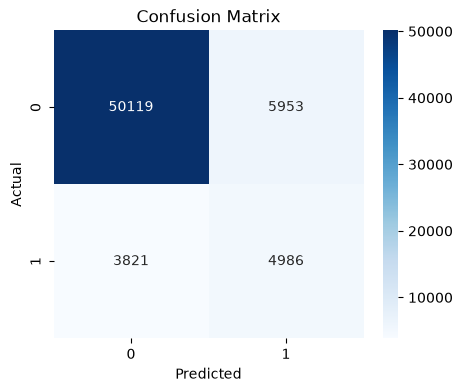

In [27]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["0", "1"], yticklabels=["0", "1"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 10. Biểu đồ 2: Precision-Recall Curve


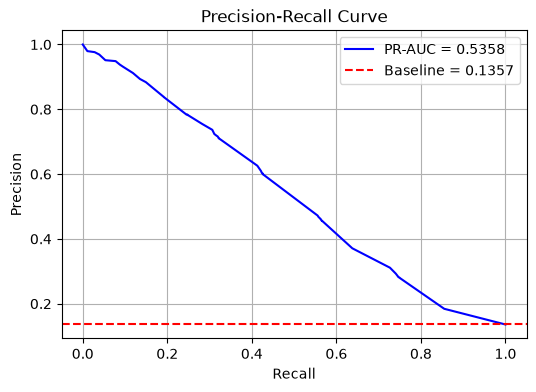

In [28]:
precision, recall, _ = precision_recall_curve(y_true, y_score)
pr_auc_val = auc(recall, precision)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="blue", label=f"PR-AUC = {pr_auc_val:.4f}")
plt.axhline(y=y_true.mean(), color="red", linestyle="--", label=f"Baseline = {y_true.mean():.4f}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.show()


# 11. Biểu đồ 3: ROC-AUC Curve


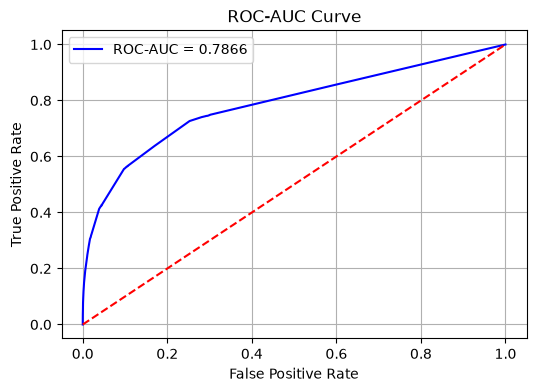

In [29]:
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color="blue", label=f"ROC-AUC = {roc_auc_val:.4f}")
plt.plot([0, 1], [0, 1], color="red", linestyle="--")
plt.title("ROC-AUC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


# 12. Xuất mô hình tốt nhất (Export Best Model & Scaler)
Lưu trữ mô hình  tối ưu và  theo chuẩn Spark MLlib Persistence để phục vụ tái lập và triển khai hệ thống gợi ý.

In [30]:
import os
import json

MODELS_DIR = "../models"
os.makedirs(MODELS_DIR, exist_ok=True)

# 1. Lưu Scaler Model và Best GBT Model theo chuẩn Apache Spark MLlib
scaler_path = os.path.join(MODELS_DIR, "scaler_model")
gbt_path = os.path.join(MODELS_DIR, "best_gbt_model")

scaler_model.write().overwrite().save(scaler_path)
gbt_model.write().overwrite().save(gbt_path)
print(f"Đã lưu StandardScalerModel vào: {scaler_path}")
print(f"Đã lưu Best GBTClassificationModel vào: {gbt_path}")

# 2. Xuất Metadata JSON phục vụ Web Serving độ trễ thấp (<2ms)
metadata = {
    "model_name": "Best_GBTClassifier_Tuned",
    "framework": "PySpark MLlib",
    "features": features,
    "feature_importances": dict(zip(features, gbt_model.featureImportances.toArray().tolist())),
    "scaler": {
        "type": "StandardScaler",
        "withMean": False,
        "withStd": True,
        "std": scaler_model.std.toArray().tolist()
    },
    "hyperparameters": {
        "maxDepth": int(d),
        "maxIter": int(it),
        "stepSize": float(gbt_model.getStepSize()),
        "weightCol": "class_weight"
    },
    "class_weights": {
        "w0": float(weight_0),
        "w1": float(weight_1)
    }
}

meta_path = os.path.join(MODELS_DIR, "best_gbt_metadata.json")
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)
print(f"Đã lưu Inference Metadata vào: {meta_path}")


Đã lưu StandardScalerModel vào: ../models/scaler_model
Đã lưu Best GBTClassificationModel vào: ../models/best_gbt_model
Đã lưu Inference Metadata vào: ../models/best_gbt_metadata.json


In [31]:
spark.stop()